# V4 Benchmark Rebuild + Zero-Shot Model Sweep

**Motivation (from V5.2 critique)**
- V3 benchmark uses group-only labels; V5.2 trains on group+category → systematic label mismatch causes v3 Spearman to appear near-chance even for good models.
- Holdout/borderline were generated with the same filter as training → in-distribution, ROC-AUC 0.994 is not a generalisation signal.
- The only genuine result was the adversarial test (ROC-AUC 0.977).

**This notebook**
1. Rebuilds the benchmark with **consistent labels** matching V5.2 training (group + Category, TF-IDF ≤ 0.30).
2. Also builds a **resolution-code benchmark** — tests whether tickets resolved the same way are semantically similar.
3. Runs a **zero-shot sweep** of five models and compares them on both benchmarks.

| Model | Notes |
|-------|-------|
| Base MPNet (`all-mpnet-base-v2`) | Untrained baseline |
| V4 Cosine (production) | Previously deployed |
| V5.2 Merged (latest) | Best trained model so far |
| `BAAI/bge-base-en-v1.5` | Hard-neg trained, 768-dim |
| `intfloat/e5-base-v2` | Instruction-tuned retrieval, 768-dim |
| `nomic-ai/nomic-embed-text-v1.5` | Large diverse training, 768-dim |

In [1]:
# ── 1. Imports & Paths ─────────────────────────────────────────────────────
import json
import gc
import random
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.stats import spearmanr
from tqdm.auto import tqdm
from sentence_transformers import SentenceTransformer
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED)

BASE      = Path(r'c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism')
DATA_NEW  = BASE / 'data_new'
CSV_PATH  = DATA_NEW / 'SNow_incident_ticket_data.csv'
MODELS_DIR = BASE / 'models' / 'real_servicenow_finetuned_mpnet_lora'

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

OUT_v4   = DATA_NEW / 'benchmark_v4_group_category.json'
OUT_rcode = DATA_NEW / 'benchmark_v4_resolution_code.json'
RESULTS_PATH = BASE / 'models' / 'eval_v3_results' / 'zero_shot_sweep_v4.json'
RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)

Device: cuda


In [2]:
# ── 2. Load & Prepare Data ─────────────────────────────────────────────────
df = pd.read_csv(CSV_PATH, encoding='utf-8', encoding_errors='replace')
print(f'Total rows: {len(df)}')

# Minimal text cleaning
df['Description'] = df['Description'].fillna('').str.strip()
df['Resolution notes'] = df['Resolution notes'].fillna('').str.strip()

# Build context-enriched text (matches training format from Cell 4 of training notebook)
def build_text(row):
    parts = []
    parts.append(f"Category: {row.get('Category', '')}")
    parts.append(f"Service: {row.get('Service', '')}")
    parts.append(f"Priority: {row.get('Priority', '')}")
    desc = str(row.get('Description', '')).strip()
    if desc:
        parts.append(f"Description: {desc}")
    return ' | '.join(p for p in parts if p.split(': ')[1].strip())

df['text'] = df.apply(build_text, axis=1)

# Drop short texts
df = df[df['text'].str.len() >= 25].reset_index(drop=True)
print(f'After length filter: {len(df)}')
print(f'Assignment groups : {df["Assignment group"].nunique()}')
print(f'Categories        : {df["Category"].nunique()} — {df["Category"].value_counts().to_dict()}')
print(f'Resolution codes  : {df["Resolution code"].nunique()}')
print(f'Top resolution codes:')
print(df['Resolution code'].value_counts().head(8).to_string())

Total rows: 10633
After length filter: 10633
Assignment groups : 26
Categories        : 4 — {'Application/Software': 9570, 'Network': 372, 'Server': 123, 'Hardware': 5}
Resolution codes  : 11
Top resolution codes:
Resolution code
Solved (Permanently)            2742
Resolved by Workaround          1958
Closed/Resolved by Requester    1663
Not an Incident                 1514
Duplicate                        785
Resolved by Change               619
User Error                       604
Resolved by Service Request      303


In [3]:
# ── 3. TF-IDF Gate Helper ─────────────────────────────────────────────────
class _TFIDFCalc:
    def __init__(self, texts, max_features=15000):
        print('Building TF-IDF...')
        self._vec = TfidfVectorizer(
            max_features=max_features, stop_words='english',
            ngram_range=(1, 2), min_df=2, max_df=0.95
        )
        self._mat = self._vec.fit_transform(texts)
        print(f'  TF-IDF matrix: {self._mat.shape}')

    def sim(self, i, j):
        return float((self._mat[i] @ self._mat[j].T).toarray()[0][0])


# ── 4. Benchmark Builder ───────────────────────────────────────────────────
def build_benchmark(
    df, label_col, label_fn,
    target_pairs=950, pos_frac=0.5,
    pos_gate=0.30, neg_gate=0.35,
    hard_neg_svc=True,
    seed=42, desc='benchmark'
):
    """
    Build a balanced benchmark with pos_gate / neg_gate TF-IDF constraints.

    label_fn(row_i, row_j) -> True (positive) | False (negative)
    hard_neg_svc: if True, draw negatives from same Service first (harder).
    """
    rng   = np.random.RandomState(seed)
    tfidf = _TFIDFCalc(df['Description'].fillna('').tolist())

    pos_target = int(target_pairs * pos_frac)
    neg_target = target_pairs - pos_target

    # Index maps
    label_groups = {}
    for idx, row in df.iterrows():
        k = row[label_col]
        if pd.notna(k):
            label_groups.setdefault(k, []).append(idx)
    label_groups = {k: v for k, v in label_groups.items() if len(v) >= 2}

    svc_idx = {s: list(ix) for s, ix in df.groupby('Service').groups.items()}
    all_idx = list(df.index)

    pairs = []

    # Positives
    pbar = tqdm(total=pos_target, desc=f'[{desc}] positives')
    attempts = 0
    while len(pairs) < pos_target and attempts < pos_target * 200:
        attempts += 1
        k  = rng.choice(list(label_groups.keys()))
        ij = rng.choice(label_groups[k], 2, replace=False)
        i, j = int(ij[0]), int(ij[1])
        if label_fn(df.loc[i], df.loc[j]) and tfidf.sim(i, j) <= pos_gate:
            pairs.append({'text1': df.at[i, 'text'], 'text2': df.at[j, 'text'],
                          'label': 1, 'tier': 'positive'})
            pbar.update(1)
    pbar.close()
    print(f'  Positives: {sum(p["label"]==1 for p in pairs)}/{pos_target}')

    # Hard negatives (cross-label, same service if hard_neg_svc, TF-IDF ≥ neg_gate threshold region)
    neg_pairs = []
    pbar = tqdm(total=neg_target, desc=f'[{desc}] negatives')
    attempts = 0
    while len(neg_pairs) < neg_target and attempts < neg_target * 200:
        attempts += 1
        i = int(rng.choice(all_idx))
        row_i = df.loc[i]
        if hard_neg_svc:
            pool = svc_idx.get(row_i['Service'], all_idx)
        else:
            pool = all_idx
        j = int(rng.choice(pool))
        if i == j: continue
        row_j = df.loc[j]
        if label_fn(row_i, row_j): continue  # positive pair — skip
        if tfidf.sim(i, j) <= neg_gate:
            neg_pairs.append({'text1': df.at[i, 'text'], 'text2': df.at[j, 'text'],
                              'label': 0, 'tier': 'hard_neg' if hard_neg_svc else 'easy_neg'})
            pbar.update(1)
    pbar.close()
    print(f'  Negatives: {len(neg_pairs)}/{neg_target}')

    pairs += neg_pairs
    rng.shuffle(pairs)
    del tfidf; gc.collect()
    return pairs

print('Helpers defined.')

Helpers defined.


In [4]:
# ── 5. Build V4 Benchmark: Group + Category (matching V5.2 training labels) ─
print('='*60)
print('Building V4 benchmark — group + Category joint label')
print('  pos_gate=0.30  neg_gate=0.35  target=950 pairs')
print('='*60)

def label_group_cat(ri, rj):
    """True iff same Assignment group AND same Category (both non-null)."""
    g1, g2 = ri['Assignment group'], rj['Assignment group']
    c1, c2 = ri['Category'], rj['Category']
    if pd.isna(g1) or pd.isna(g2) or pd.isna(c1) or pd.isna(c2): return False
    return g1 == g2 and c1 == c2

if OUT_v4.exists():
    print(f'[LOAD] {OUT_v4}')
    v4_pairs = json.loads(OUT_v4.read_text(encoding='utf-8'))
else:
    v4_pairs = build_benchmark(
        df, label_col='Assignment group',
        label_fn=label_group_cat,
        target_pairs=950, pos_frac=0.5,
        pos_gate=0.30, neg_gate=0.35,
        hard_neg_svc=True, seed=SEED, desc='v4-group+cat'
    )
    OUT_v4.write_text(json.dumps(v4_pairs, ensure_ascii=False), encoding='utf-8')
    print(f'[SAVE] {OUT_v4}')

pos_n = sum(p['label']==1 for p in v4_pairs)
print(f'\nV4 benchmark: {len(v4_pairs)} pairs | pos={pos_n} neg={len(v4_pairs)-pos_n}')

Building V4 benchmark — group + Category joint label
  pos_gate=0.30  neg_gate=0.35  target=950 pairs
[LOAD] c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data_new\benchmark_v4_group_category.json

V4 benchmark: 950 pairs | pos=475 neg=475


In [5]:
# ── 6. Build Resolution-Code Benchmark ─────────────────────────────────────
# Resolution code is 100% filled, 11 distinct values — tests whether tickets
# resolved the same way (e.g. "Solved (Permanently)") are semantically similar.
# Positives: same resolution code, TF-IDF ≤ 0.30
# The hypothesis: an analyst searching for reusable resolutions cares about
# resolution-similarity more than routing-similarity.

# Filter to resolution codes with enough examples (≥ 20)
freq = df['Resolution code'].value_counts()
valid_codes = set(freq[freq >= 20].index)
df_rc = df[df['Resolution code'].isin(valid_codes)].reset_index(drop=True)
print(f'Resolution code benchmark — {len(df_rc)} rows with ≥20-member codes')
print(f'Valid codes ({len(valid_codes)}): {sorted(valid_codes)}')

def label_rescode(ri, rj):
    rc1, rc2 = ri['Resolution code'], rj['Resolution code']
    if pd.isna(rc1) or pd.isna(rc2): return False
    return rc1 == rc2

if OUT_rcode.exists():
    print(f'[LOAD] {OUT_rcode}')
    rcode_pairs = json.loads(OUT_rcode.read_text(encoding='utf-8'))
else:
    rcode_pairs = build_benchmark(
        df_rc, label_col='Resolution code',
        label_fn=label_rescode,
        target_pairs=950, pos_frac=0.5,
        pos_gate=0.30, neg_gate=0.35,
        hard_neg_svc=False,  # resolution codes cut across services
        seed=SEED, desc='v4-rescode'
    )
    OUT_rcode.write_text(json.dumps(rcode_pairs, ensure_ascii=False), encoding='utf-8')
    print(f'[SAVE] {OUT_rcode}')

pos_n = sum(p['label']==1 for p in rcode_pairs)
print(f'\nResolution-code benchmark: {len(rcode_pairs)} pairs | pos={pos_n} neg={len(rcode_pairs)-pos_n}')

Resolution code benchmark — 10446 rows with ≥20-member codes
Valid codes (10): ['Closed/Resolved by Requester', 'Duplicate', 'Not Solved (Not Reproducible)', 'Not an Incident', 'Resolved by Change', 'Resolved by Problem', 'Resolved by Service Request', 'Resolved by Workaround', 'Solved (Permanently)', 'User Error']
[LOAD] c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data_new\benchmark_v4_resolution_code.json

Resolution-code benchmark: 950 pairs | pos=475 neg=475


In [13]:
# ── 7. Evaluation Helper ───────────────────────────────────────────────────
def eval_model_on_benchmark(model, pairs, batch_size=32, prefix_query='', prefix_doc=''):
    """
    Encode all pairs and compute Spearman, ROC-AUC, PR-AUC.
    prefix_query / prefix_doc: instruction prefixes for e5 / nomic models.
    """
    texts1 = [prefix_query + p['text1'] for p in pairs]
    texts2 = [prefix_doc  + p['text2'] for p in pairs]
    labels = np.array([p['label'] for p in pairs], dtype=float)

    emb1 = model.encode(texts1, batch_size=batch_size, show_progress_bar=True,
                        convert_to_numpy=True, normalize_embeddings=True)
    emb2 = model.encode(texts2, batch_size=batch_size, show_progress_bar=True,
                        convert_to_numpy=True, normalize_embeddings=True)

    scores = (emb1 * emb2).sum(axis=1)  # dot = cosine when normalised

    spearman, _  = spearmanr(labels, scores)
    roc_auc      = roc_auc_score(labels, scores)
    pr_auc       = average_precision_score(labels, scores)
    pos_mean     = float(scores[labels == 1].mean())
    neg_mean     = float(scores[labels == 0].mean())
    delta        = pos_mean - neg_mean

    return {
        'spearman': round(float(spearman), 4),
        'roc_auc' : round(float(roc_auc),  4),
        'pr_auc'  : round(float(pr_auc),   4),
        'pos_mean': round(pos_mean, 4),
        'neg_mean': round(neg_mean, 4),
        'delta'   : round(delta, 4),
    }


# Models to sweep
NOMIC_V53_PATH = str(BASE / 'models' / 'real_servicenow_finetuned_nomic_lora' / 'real_servicenow_v2_20260302_1754_merged')

SWEEP = [
    {
        'name'        : 'Base MPNet',
        'path'        : 'sentence-transformers/all-mpnet-base-v2',
        'prefix_query': '',
        'prefix_doc'  : '',
    },
    {
        'name'        : 'V4 Cosine (production)',
        'path'        : str(MODELS_DIR / 'real_servicenow_v2_20260104_2321'),
        'prefix_query': '',
        'prefix_doc'  : '',
    },
    {
        'name'        : 'V5.2 Merged (latest)',
        'path'        : str(MODELS_DIR / 'real_servicenow_v2_20260225_1841_merged'),
        'prefix_query': '',
        'prefix_doc'  : '',
    },
    {
        'name'             : 'V5.3 Nomic (fine-tuned)',
        'path'             : NOMIC_V53_PATH,
        'prefix_query'     : '',
        'prefix_doc'       : '',
        'trust_remote_code': True,
    },
    {
        'name'        : 'BGE-base-en-v1.5',
        'path'        : 'BAAI/bge-base-en-v1.5',
        'prefix_query': 'Represent this sentence for searching relevant passages: ',
        'prefix_doc'  : '',
    },
    {
        'name'        : 'E5-base-v2',
        'path'        : 'intfloat/e5-base-v2',
        'prefix_query': 'query: ',
        'prefix_doc'  : 'passage: ',
    },
    {
        'name'             : 'Nomic-embed-text-v1.5',
        'path'             : 'nomic-ai/nomic-embed-text-v1.5',
        'prefix_query'     : 'search_query: ',
        'prefix_doc'       : 'search_document: ',
        'trust_remote_code': True,
    },
]

print(f'Sweep: {len(SWEEP)} models')
print(f'V5.3 Nomic path: {NOMIC_V53_PATH}')


Sweep: 7 models
V5.3 Nomic path: c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\real_servicenow_finetuned_nomic_lora\real_servicenow_v2_20260302_1754_merged


In [7]:
# ── 8. Run Sweep ───────────────────────────────────────────────────────────
results = {}  # {model_name: {benchmark: metrics}}

benchmarks = {
    'v4_group_cat'   : v4_pairs,
    'v4_rescode'     : rcode_pairs,
}

for spec in SWEEP:
    name = spec['name']
    print(f'\n{"="*60}')
    print(f'Loading: {name}')
    print('='*60)

    try:
        kwargs = {'device': DEVICE}
        if spec.get('trust_remote_code'):
            kwargs['trust_remote_code'] = True
        m = SentenceTransformer(spec['path'], **kwargs)
    except Exception as e:
        print(f'[SKIP] Failed to load {name}: {e}')
        results[name] = {'error': str(e)}
        continue

    results[name] = {}
    for bname, bpairs in benchmarks.items():
        print(f'\n  Evaluating on {bname} ({len(bpairs)} pairs)...')
        try:
            metrics = eval_model_on_benchmark(
                m, bpairs, batch_size=32,
                prefix_query=spec.get('prefix_query', ''),
                prefix_doc  =spec.get('prefix_doc',   ''),
            )
            results[name][bname] = metrics
            print(f'  Spearman={metrics["spearman"]:.4f}  '
                  f'ROC-AUC={metrics["roc_auc"]:.4f}  '
                  f'Δ(pos-neg)={metrics["delta"]:+.4f}')
        except Exception as e:
            print(f'  [ERROR] {e}')
            results[name][bname] = {'error': str(e)}

    del m
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
    gc.collect()

# Save results
RESULTS_PATH.write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding='utf-8')
print(f'\n[SAVE] Results → {RESULTS_PATH}')


Loading: Base MPNet


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



  Evaluating on v4_group_cat (950 pairs)...


Batches:   0%|          | 0/30 [00:00<?, ?it/s]

Batches:   0%|          | 0/30 [00:00<?, ?it/s]

... (45 outputs left out)

  Spearman=0.0248  ROC-AUC=0.5143  Δ(pos-neg)=+0.0018

  Evaluating on v4_rescode (950 pairs)...


Batches:   0%|          | 0/30 [00:00<?, ?it/s]

Batches:   0%|          | 0/30 [00:00<?, ?it/s]

  Spearman=0.1258  ROC-AUC=0.5726  Δ(pos-neg)=+0.0218

[SAVE] Results → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v3_results\zero_shot_sweep_v4.json


In [8]:
# ── 9. Results Table ───────────────────────────────────────────────────────
rows = []
for model_name, bmark_results in results.items():
    if 'error' in bmark_results:
        rows.append({'Model': model_name, 'Benchmark': 'N/A',
                     'Spearman': None, 'ROC-AUC': None, 'Δ(pos-neg)': None})
        continue
    for bname, metrics in bmark_results.items():
        if 'error' in metrics:
            rows.append({'Model': model_name, 'Benchmark': bname,
                         'Spearman': None, 'ROC-AUC': None, 'Δ(pos-neg)': None})
        else:
            rows.append({
                'Model'     : model_name,
                'Benchmark' : bname,
                'Spearman'  : metrics['spearman'],
                'ROC-AUC'   : metrics['roc_auc'],
                'PR-AUC'    : metrics['pr_auc'],
                'Δ(pos-neg)': metrics['delta'],
                'pos_mean'  : metrics['pos_mean'],
                'neg_mean'  : metrics['neg_mean'],
            })

df_res = pd.DataFrame(rows)

print('\n' + '='*80)
print('ZERO-SHOT SWEEP RESULTS')
print('='*80)

for bname in df_res['Benchmark'].unique():
    sub = df_res[df_res['Benchmark'] == bname].copy()
    sub = sub.drop('Benchmark', axis=1).sort_values('Spearman', ascending=False)
    print(f'\n── Benchmark: {bname} ──')
    print(sub.to_string(index=False))

print('\n' + '='*80)
print('VERDICT')
print('='*80)

try:
    v4_sub = df_res[df_res['Benchmark'] == 'v4_group_cat'].set_index('Model')
    best = v4_sub['Spearman'].idxmax()
    best_sp = v4_sub.loc[best, 'Spearman']
    v52_sp  = v4_sub.loc['V5.2 Merged (latest)', 'Spearman'] if 'V5.2 Merged (latest)' in v4_sub.index else None
    base_sp = v4_sub.loc['Base MPNet', 'Spearman'] if 'Base MPNet' in v4_sub.index else None

    print(f'Best model on v4_group_cat : {best} (Spearman={best_sp:.4f})')
    if v52_sp: print(f'V5.2 vs best              : {v52_sp:.4f} vs {best_sp:.4f}')
    if base_sp: print(f'V5.2 vs Base MPNet        : {v52_sp:.4f} vs {base_sp:.4f}')

    new_models = [s['name'] for s in SWEEP if s['name'] not in ('Base MPNet', 'V4 Cosine (production)', 'V5.2 Merged (latest)')]
    for nm in new_models:
        if nm in v4_sub.index:
            nm_sp = v4_sub.loc[nm, 'Spearman']
            if v52_sp and nm_sp > v52_sp:
                print(f'  [PIVOT] {nm} beats V5.2 ({nm_sp:.4f} > {v52_sp:.4f}) — consider fine-tuning on top of this base')
            else:
                print(f'  [OK]    {nm} ({nm_sp:.4f}) — V5.2 is competitive')
except Exception as e:
    print(f'Verdict error: {e}')


ZERO-SHOT SWEEP RESULTS

── Benchmark: v4_group_cat ──
                 Model  Spearman  ROC-AUC  PR-AUC  Δ(pos-neg)  pos_mean  neg_mean
 Nomic-embed-text-v1.5    0.0248   0.5143  0.4900      0.0018    0.7724    0.7706
            E5-base-v2   -0.0150   0.4913  0.4772     -0.0028    0.8383    0.8412
  V5.2 Merged (latest)   -0.0223   0.4871  0.4971     -0.0137    0.6999    0.7136
      BGE-base-en-v1.5   -0.0327   0.4811  0.4715     -0.0115    0.6790    0.6906
V4 Cosine (production)   -0.0913   0.4473  0.4555     -0.0354    0.5000    0.5354
            Base MPNet   -0.0922   0.4468  0.4557     -0.0351    0.4997    0.5349

── Benchmark: v4_rescode ──
                 Model  Spearman  ROC-AUC  PR-AUC  Δ(pos-neg)  pos_mean  neg_mean
 Nomic-embed-text-v1.5    0.1258   0.5726  0.5596      0.0218    0.7395    0.7177
      BGE-base-en-v1.5    0.1129   0.5652  0.5566      0.0233    0.6832    0.6599
  V5.2 Merged (latest)    0.1128   0.5651  0.5540      0.0508    0.4759    0.4251
V4 Cosine (pr

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (12 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: intfloat/e5-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: intfloat/e5-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
<All keys matched successfully>
<All keys matched successfully>


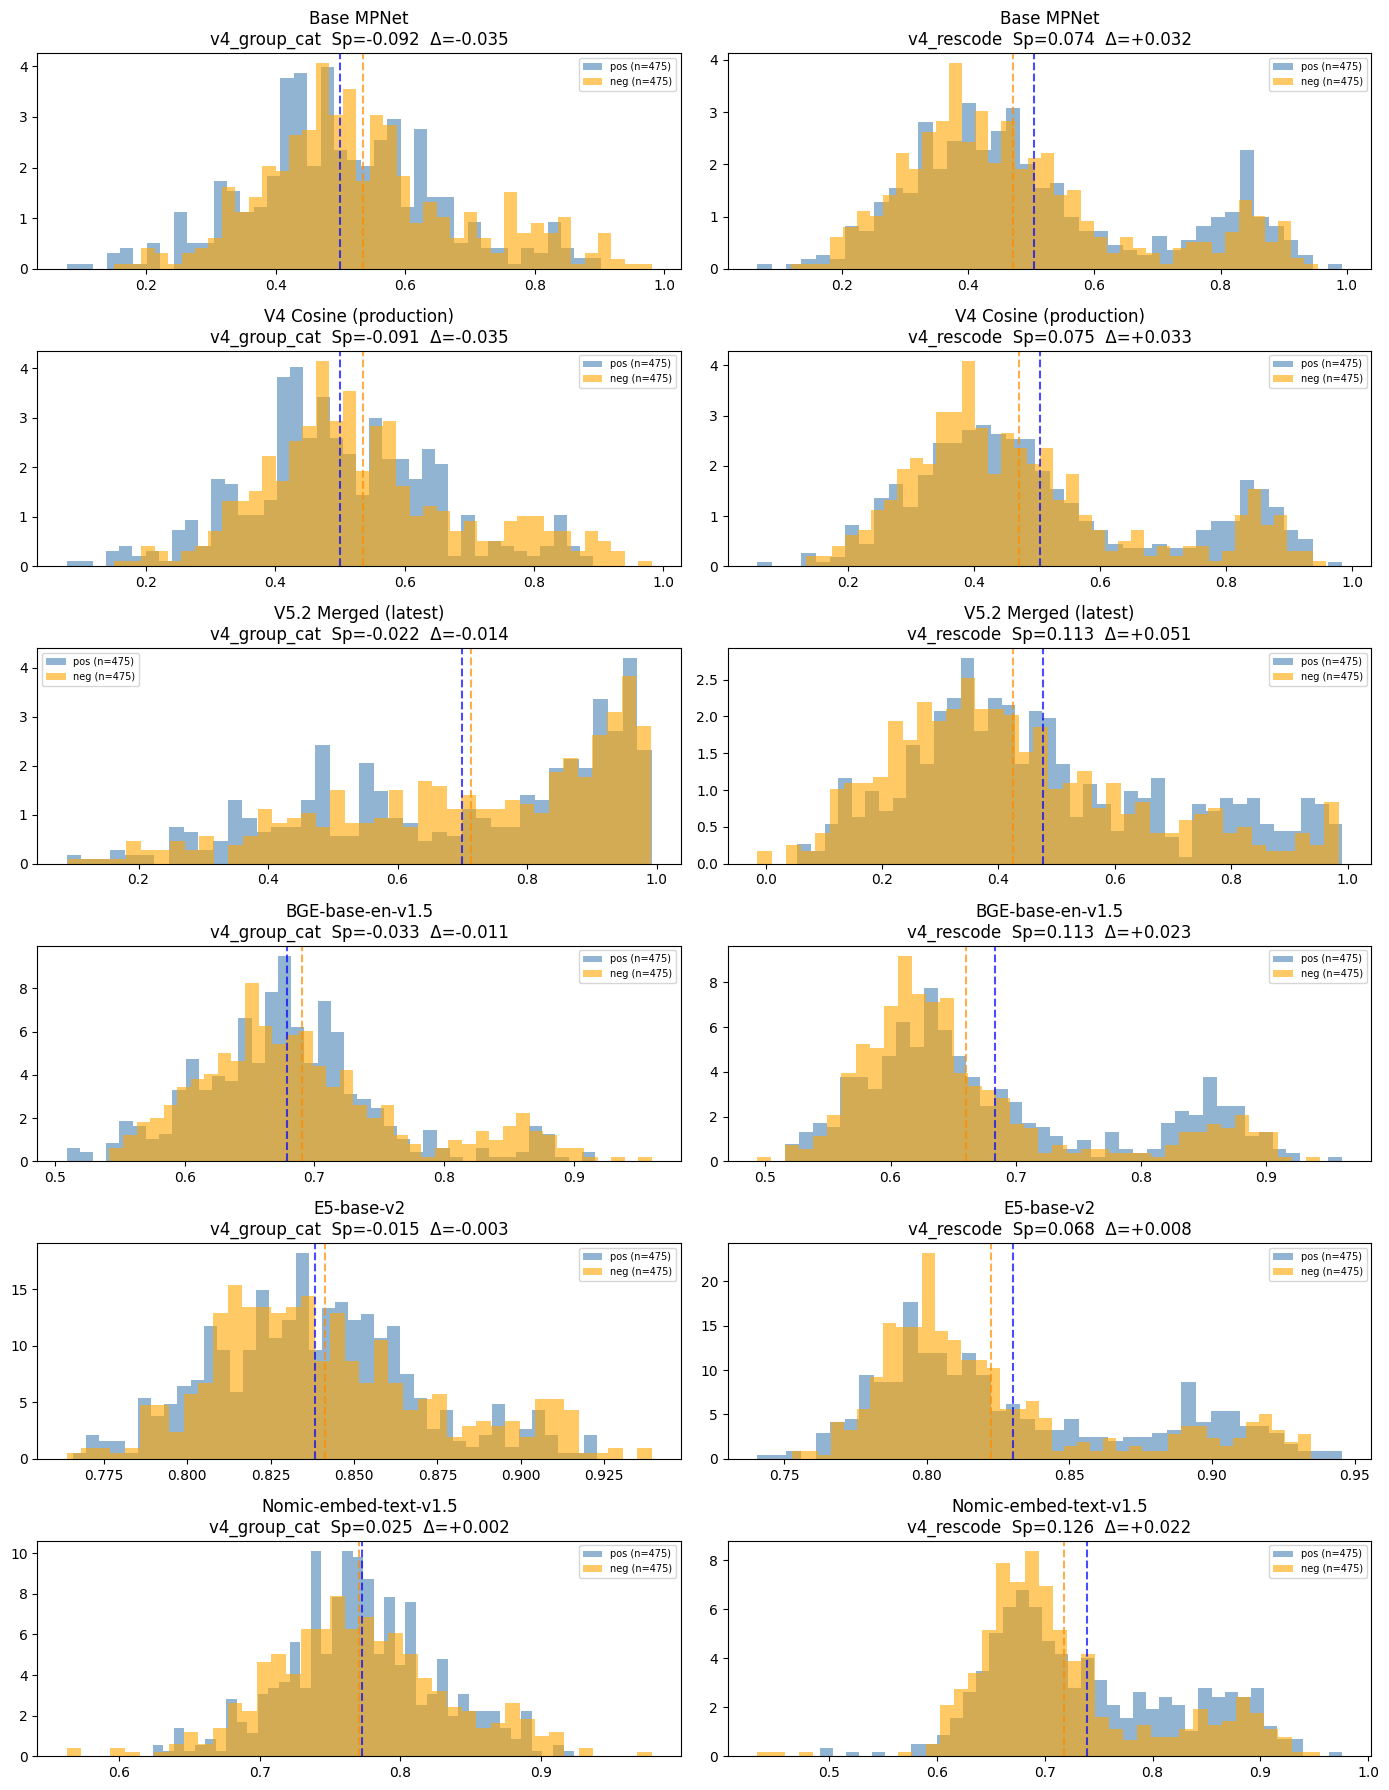

[SAVE] c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v3_results\zero_shot_distributions.png


In [9]:
# ── 10. Score Distribution Plot ────────────────────────────────────────────
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(SWEEP), 2, figsize=(14, 3 * len(SWEEP)), squeeze=False)
benchmark_list = list(benchmarks.items())

for row_idx, spec in enumerate(SWEEP):
    name = spec['name']
    for col_idx, (bname, bpairs) in enumerate(benchmark_list):
        ax = axes[row_idx][col_idx]
        bm = results.get(name, {}).get(bname, {})
        if 'error' in bm or not bm:
            ax.set_title(f'{name}\n{bname} — N/A')
            ax.axis('off')
            continue

        # Re-encode to get score distributions
        try:
            kwargs = {'device': DEVICE}
            if spec.get('trust_remote_code'):
                kwargs['trust_remote_code'] = True
            m = SentenceTransformer(spec['path'], **kwargs)
            texts1 = [spec.get('prefix_query','') + p['text1'] for p in bpairs]
            texts2 = [spec.get('prefix_doc','')   + p['text2'] for p in bpairs]
            labels = np.array([p['label'] for p in bpairs])
            e1 = m.encode(texts1, batch_size=32, convert_to_numpy=True, 
                          normalize_embeddings=True, show_progress_bar=False)
            e2 = m.encode(texts2, batch_size=32, convert_to_numpy=True, 
                          normalize_embeddings=True, show_progress_bar=False)
            scores = (e1 * e2).sum(axis=1)
            del m, e1, e2
            if DEVICE == 'cuda': torch.cuda.empty_cache()
            gc.collect()

            ax.hist(scores[labels==1], bins=40, alpha=0.6, color='steelblue',
                    label=f'pos (n={labels.sum()})', density=True)
            ax.hist(scores[labels==0], bins=40, alpha=0.6, color='orange',
                    label=f'neg (n={(labels==0).sum()})', density=True)
            ax.axvline(bm['pos_mean'], color='blue', linestyle='--', alpha=0.7)
            ax.axvline(bm['neg_mean'], color='darkorange', linestyle='--', alpha=0.7)
            ax.set_title(f'{name}\n{bname}  Sp={bm["spearman"]:.3f}  Δ={bm["delta"]:+.3f}')
            ax.legend(fontsize=7)
        except Exception as e:
            ax.set_title(f'{name}\n{bname} — plot error')
            ax.text(0.5, 0.5, str(e), transform=ax.transAxes, fontsize=7)

plt.tight_layout()
plot_path = RESULTS_PATH.parent / 'zero_shot_distributions.png'
plt.savefig(plot_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'[SAVE] {plot_path}')

In [10]:

# ── 11. Build Semantic Benchmark: Resolution-Notes TF-IDF Ground Truth ─────
#
# Motivation: Previous benchmarks use routing labels (group+category) or
# coarse resolution codes — neither correlates reliably with description
# semantics. Here we use TF-IDF cosine similarity of RESOLUTION NOTES as
# the ground truth signal.
#
# Positive pair  : res_notes_tfidf_sim(i,j) >= 0.15  →  similar solutions
# Negative pair  : res_notes_tfidf_sim(i,j) <= 0.03  →  clearly different solutions
# Extra gate     : description_tfidf_sim(i,j) <= 0.40 on positives
#                  (prevents copy-paste tickets from trivially inflating cosine)
# Min note length: 80 chars — removes stubs like "Closed by Caller"
#
# The hypothesis: a model that genuinely understands ITSM semantics should
# score description pairs higher when their resolutions are similar,
# even though it never sees the resolution notes at inference time.

OUT_semantic = DATA_NEW / 'benchmark_v4_semantic_resnotes.json'

def build_semantic_benchmark(
    df, target_pairs=950, pos_frac=0.5,
    pos_rn_threshold=0.15,   # min res-notes TF-IDF sim to be positive
    neg_rn_threshold=0.03,   # max res-notes TF-IDF sim to be negative
    desc_gate=0.40,           # max description TF-IDF sim on positives (anti-duplicate gate)
    min_note_len=80,          # minimum resolution notes length to enter pool
    seed=42
):
    rng = np.random.RandomState(seed)

    # 1. Filter to rows with substantive resolution notes
    pool = df[df['Resolution notes'].str.len() >= min_note_len].reset_index(drop=True)
    print(f'  Pool after min_note_len≥{min_note_len}: {len(pool)} rows')

    # 2. Build TF-IDF over resolution notes
    print('  Building TF-IDF on resolution notes...')
    rn_vec = TfidfVectorizer(
        max_features=15000, stop_words='english',
        ngram_range=(1, 2), min_df=2, max_df=0.95
    )
    rn_mat = rn_vec.fit_transform(pool['Resolution notes'].tolist())
    print(f'  RN TF-IDF matrix: {rn_mat.shape}')

    # 3. Build TF-IDF over descriptions (for anti-duplicate gate on positives)
    print('  Building TF-IDF on descriptions...')
    desc_vec = TfidfVectorizer(
        max_features=15000, stop_words='english',
        ngram_range=(1, 2), min_df=2, max_df=0.95
    )
    desc_mat = desc_vec.fit_transform(pool['Description'].tolist())
    print(f'  Desc TF-IDF matrix: {desc_mat.shape}')

    def rn_sim(i, j):
        return float((rn_mat[i] @ rn_mat[j].T).toarray()[0][0])

    def desc_sim(i, j):
        return float((desc_mat[i] @ desc_mat[j].T).toarray()[0][0])

    all_idx  = list(range(len(pool)))
    pos_target = int(target_pairs * pos_frac)
    neg_target = target_pairs - pos_target

    # ── Positives ──────────────────────────────────────────────────────────
    pos_pairs = []
    pbar = tqdm(total=pos_target, desc='[semantic] positives')
    attempts = 0
    while len(pos_pairs) < pos_target and attempts < pos_target * 400:
        attempts += 1
        i, j = rng.choice(all_idx, 2, replace=False)
        i, j = int(i), int(j)
        if rn_sim(i, j) >= pos_rn_threshold and desc_sim(i, j) <= desc_gate:
            pos_pairs.append({
                'text1': pool.at[i, 'text'],
                'text2': pool.at[j, 'text'],
                'rn_sim': round(rn_sim(i, j), 4),
                'label': 1,
                'tier': 'semantic_positive',
                # Store notes for sanity check (stripped to 120 chars)
                '_rn1': pool.at[i, 'Resolution notes'][:120],
                '_rn2': pool.at[j, 'Resolution notes'][:120],
            })
            pbar.update(1)
    pbar.close()
    print(f'  Positives collected: {len(pos_pairs)}/{pos_target}  (attempts={attempts})')

    # ── Negatives ──────────────────────────────────────────────────────────
    neg_pairs = []
    pbar = tqdm(total=neg_target, desc='[semantic] negatives')
    attempts = 0
    while len(neg_pairs) < neg_target and attempts < neg_target * 400:
        attempts += 1
        i, j = rng.choice(all_idx, 2, replace=False)
        i, j = int(i), int(j)
        if rn_sim(i, j) <= neg_rn_threshold:
            neg_pairs.append({
                'text1': pool.at[i, 'text'],
                'text2': pool.at[j, 'text'],
                'rn_sim': round(rn_sim(i, j), 4),
                'label': 0,
                'tier': 'semantic_negative',
            })
            pbar.update(1)
    pbar.close()
    print(f'  Negatives collected: {len(neg_pairs)}/{neg_target}  (attempts={attempts})')

    pairs = pos_pairs + neg_pairs
    rng.shuffle(pairs)
    del rn_mat, desc_mat
    gc.collect()
    return pairs, pool


if OUT_semantic.exists():
    print(f'[LOAD] {OUT_semantic}')
    semantic_pairs = json.loads(OUT_semantic.read_text(encoding='utf-8'))
    # Rebuild pool for sanity check
    pool_rn = df[df['Resolution notes'].str.len() >= 80].reset_index(drop=True)
else:
    print('='*60)
    print('Building Semantic benchmark — res-notes TF-IDF ground truth')
    print(f'  pos_rn≥0.15  neg_rn≤0.03  desc_gate≤0.40  min_note=80  target=950')
    print('='*60)
    semantic_pairs, pool_rn = build_semantic_benchmark(df, target_pairs=950, seed=SEED)
    OUT_semantic.write_text(json.dumps(semantic_pairs, ensure_ascii=False), encoding='utf-8')
    print(f'[SAVE] {OUT_semantic}')

pos_n = sum(p['label']==1 for p in semantic_pairs)
print(f'\nSemantic benchmark: {len(semantic_pairs)} pairs | pos={pos_n} neg={len(semantic_pairs)-pos_n}')

# ── Sanity check: print 3 positive examples ───────────────────────────────
print('\n── Sanity check: 3 positive pairs (should have similar resolutions) ──')
shown = 0
for p in semantic_pairs:
    if p['label'] == 1 and shown < 3:
        rn1 = p.get('_rn1', '(no note stored)')
        rn2 = p.get('_rn2', '(no note stored)')
        print(f'\n  rn_sim={p.get("rn_sim","?"):.3f}')
        print(f'  RN1: {rn1}')
        print(f'  RN2: {rn2}')
        shown += 1

print('\n── Sanity check: 3 negative pairs (should have unrelated resolutions) ──')
shown = 0
for p in semantic_pairs:
    if p['label'] == 0 and shown < 3:
        rn1 = p.get('_rn1', '(neg — no note stored)')
        rn2 = p.get('_rn2', '(neg — no note stored)')
        print(f'\n  rn_sim={p.get("rn_sim","?"):.4f}')
        shown += 1


[LOAD] c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data_new\benchmark_v4_semantic_resnotes.json

Semantic benchmark: 950 pairs | pos=475 neg=475

── Sanity check: 3 positive pairs (should have similar resolutions) ──

  rn_sim=0.332
  RN1: Issue: KL Counter Haziq PM-WO-2405000267. When generate invoice encounter error message.
Action planned taken by AMS: D
  RN2: Issue: PACMY-SO-2504000035 NOT SYNC TO SAP
Action planned taken by AMS: User asked to close the ticket. No action to be

  rn_sim=0.232
  RN1: Issue: The IDoc has processed but IBD has not created in PO 7121000336-line item 10.
Category: SAP IBD creation
Failur
  RN2: Issue: Fixed Asset Issue
Category: SAP FI FA
Failure Point: NA
Root Cause: wrong procedure
Fix: By transfer to corre

  rn_sim=0.343
  RN1: Issue: PM-WO-2409001200 ~ PART CANCELLED STATUS NOT CHANGE. 
Action planned taken by AMS: Part Order status is updated.
  RN2: Issue: ASC Galaxy Ace PM-WO-2412003918 - Request to update the WO in-warranty

In [14]:

# ── 12. Sweep All Models on Semantic Benchmark ─────────────────────────────
# Re-use eval_model_on_benchmark() and SWEEP from Cell 7.
# Merge results into the existing `results` dict, then save.

SEMANTIC_BNAME = 'v4_semantic_resnotes'

# Strip stored note fields before encoding (they're for sanity-check only)
_sem_pairs_clean = [
    {k: v for k, v in p.items() if not k.startswith('_')}
    for p in semantic_pairs
]

for spec in SWEEP:
    name = spec['name']
    if SEMANTIC_BNAME in results.get(name, {}):
        print(f'[SKIP] {name} already evaluated on {SEMANTIC_BNAME}')
        continue

    print(f'\n{"="*60}')
    print(f'Loading: {name}')
    print('='*60)

    try:
        kwargs = {'device': DEVICE}
        if spec.get('trust_remote_code'):
            kwargs['trust_remote_code'] = True
        m = SentenceTransformer(spec['path'], **kwargs)
    except Exception as e:
        print(f'[SKIP] Failed to load {name}: {e}')
        results.setdefault(name, {})[SEMANTIC_BNAME] = {'error': str(e)}
        continue

    print(f'\n  Evaluating on {SEMANTIC_BNAME} ({len(_sem_pairs_clean)} pairs)...')
    try:
        metrics = eval_model_on_benchmark(
            m, _sem_pairs_clean, batch_size=32,
            prefix_query=spec.get('prefix_query', ''),
            prefix_doc  =spec.get('prefix_doc',   ''),
        )
        results.setdefault(name, {})[SEMANTIC_BNAME] = metrics
        print(f'  Spearman={metrics["spearman"]:.4f}  '
              f'ROC-AUC={metrics["roc_auc"]:.4f}  '
              f'PR-AUC={metrics["pr_auc"]:.4f}  '
              f'Δ(pos-neg)={metrics["delta"]:+.4f}')
    except Exception as e:
        print(f'  [ERROR] {e}')
        results.setdefault(name, {})[SEMANTIC_BNAME] = {'error': str(e)}

    del m
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
    gc.collect()

# Persist updated results
RESULTS_PATH.write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding='utf-8')
print(f'\n[SAVE] Results → {RESULTS_PATH}')


[SKIP] Base MPNet already evaluated on v4_semantic_resnotes
[SKIP] V4 Cosine (production) already evaluated on v4_semantic_resnotes
[SKIP] V5.2 Merged (latest) already evaluated on v4_semantic_resnotes

Loading: V5.3 Nomic (fine-tuned)


<All keys matched successfully>



  Evaluating on v4_semantic_resnotes (950 pairs)...


Batches:   0%|          | 0/30 [00:00<?, ?it/s]

Batches:   0%|          | 0/30 [00:00<?, ?it/s]

  Spearman=0.2040  ROC-AUC=0.6178  PR-AUC=0.6334  Δ(pos-neg)=+0.0544
[SKIP] BGE-base-en-v1.5 already evaluated on v4_semantic_resnotes
[SKIP] E5-base-v2 already evaluated on v4_semantic_resnotes
[SKIP] Nomic-embed-text-v1.5 already evaluated on v4_semantic_resnotes

[SAVE] Results → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v3_results\zero_shot_sweep_v4.json


3-BENCHMARK COMPARISON — Spearman | ROC-AUC | Δ(pos-neg)

── v4_group_cat ──
                  Model  Spearman  ROC-AUC  PR-AUC       Δ  pos_mean  neg_mean
  Nomic-embed-text-v1.5    0.0248   0.5143  0.4900  0.0018    0.7724    0.7706
             E5-base-v2   -0.0150   0.4913  0.4772 -0.0028    0.8383    0.8412
   V5.2 Merged (latest)   -0.0223   0.4871  0.4971 -0.0137    0.6999    0.7136
       BGE-base-en-v1.5   -0.0327   0.4811  0.4715 -0.0115    0.6790    0.6906
 V4 Cosine (production)   -0.0913   0.4473  0.4555 -0.0354    0.5000    0.5354
             Base MPNet   -0.0922   0.4468  0.4557 -0.0351    0.4997    0.5349
V5.3 Nomic (fine-tuned)       NaN      NaN     NaN     NaN       NaN       NaN

── v4_rescode ──
                  Model  Spearman  ROC-AUC  PR-AUC      Δ  pos_mean  neg_mean
  Nomic-embed-text-v1.5    0.1258   0.5726  0.5596 0.0218    0.7395    0.7177
       BGE-base-en-v1.5    0.1129   0.5652  0.5566 0.0233    0.6832    0.6599
   V5.2 Merged (latest)    0.1128   0.5

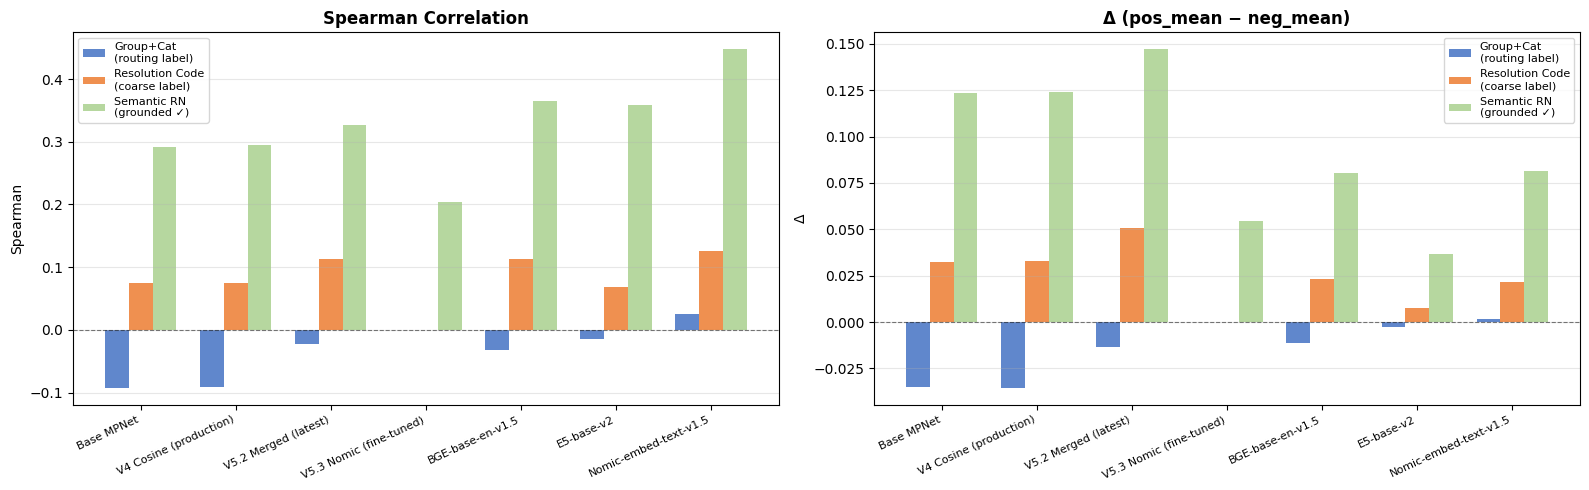

[SAVE] c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v3_results\three_benchmark_comparison.png

VERDICT — Semantic RN Benchmark (grounded ground truth)
Best model (grounded): Nomic-embed-text-v1.5 — Spearman=0.4476
  Base MPNet                           Sp=0.2920  Δ=+0.1233  
  V4 Cosine (production)               Sp=0.2949  Δ=+0.1239  
  V5.2 Merged (latest)                 Sp=0.3269  Δ=+0.1471  

  V5.3 Nomic (fine-tuned)              Sp=0.2040  [OK — V5.2 competitive]  
  BGE-base-en-v1.5                     Sp=0.3654  [PIVOT — fine-tune on this base]  
  E5-base-v2                           Sp=0.3579  [PIVOT — fine-tune on this base]  
  Nomic-embed-text-v1.5                Sp=0.4476  [PIVOT — fine-tune on this base]  ★ BEST


In [15]:

# ── 13. Unified 3-Benchmark Comparison Table ────────────────────────────────
import matplotlib.pyplot as plt

ALL_BENCHMARKS = ['v4_group_cat', 'v4_rescode', 'v4_semantic_resnotes']
BNAME_LABELS   = {
    'v4_group_cat'        : 'Group+Cat\n(routing label)',
    'v4_rescode'          : 'Resolution Code\n(coarse label)',
    'v4_semantic_resnotes': 'Semantic RN\n(grounded ✓)',
}
MODEL_ORDER = [s['name'] for s in SWEEP]

# ── (A) Full numeric table ─────────────────────────────────────────────────
print('=' * 95)
print('3-BENCHMARK COMPARISON — Spearman | ROC-AUC | Δ(pos-neg)')
print('=' * 95)

rows_all = []
for name in MODEL_ORDER:
    for bname in ALL_BENCHMARKS:
        m = results.get(name, {}).get(bname, {})
        rows_all.append({
            'Model'    : name,
            'Benchmark': bname,
            'Spearman' : m.get('spearman'),
            'ROC-AUC'  : m.get('roc_auc'),
            'PR-AUC'   : m.get('pr_auc'),
            'Δ'        : m.get('delta'),
            'pos_mean' : m.get('pos_mean'),
            'neg_mean' : m.get('neg_mean'),
        })
df_all = pd.DataFrame(rows_all)

for bname in ALL_BENCHMARKS:
    sub = df_all[df_all['Benchmark'] == bname].copy()
    sub = sub.drop('Benchmark', axis=1).sort_values('Spearman', ascending=False)
    print(f'\n── {bname} ──')
    print(sub.to_string(index=False))

# ── (B) Pivot: model × benchmark, Spearman only ───────────────────────────
print('\n' + '=' * 95)
print('SPEARMAN PIVOT  (best Spearman per benchmark highlighted)')
print('=' * 95)

pivot = df_all.pivot_table(index='Model', columns='Benchmark', values='Spearman')
pivot = pivot.reindex(MODEL_ORDER)[ALL_BENCHMARKS]
print(pivot.round(4).to_string())

# ── (C) Delta pivot ────────────────────────────────────────────────────────
print('\n' + '=' * 95)
print('Δ(pos-neg) PIVOT  (larger = better separation)')
print('=' * 95)
delta_pivot = df_all.pivot_table(index='Model', columns='Benchmark', values='Δ')
delta_pivot = delta_pivot.reindex(MODEL_ORDER)[ALL_BENCHMARKS]
print(delta_pivot.round(4).to_string())

# ── (D) Bar chart ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

x = np.arange(len(MODEL_ORDER))
width = 0.25
colors = ['#4472C4', '#ED7D31', '#A9D18E']

for ax, metric, title in zip(
    axes,
    ['Spearman', 'Δ'],
    ['Spearman Correlation', 'Δ (pos_mean − neg_mean)']
):
    for k, bname in enumerate(ALL_BENCHMARKS):
        vals = [
            df_all[(df_all['Model'] == m) & (df_all['Benchmark'] == bname)][metric].values
            for m in MODEL_ORDER
        ]
        vals = [v[0] if len(v) and v[0] is not None else 0.0 for v in vals]
        bars = ax.bar(x + k * width, vals, width, label=BNAME_LABELS[bname],
                      color=colors[k], alpha=0.85)

    ax.axhline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
    ax.set_xticks(x + width)
    ax.set_xticklabels(MODEL_ORDER, rotation=25, ha='right', fontsize=8)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=8)
    ax.set_ylabel(metric)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plot_path2 = RESULTS_PATH.parent / 'three_benchmark_comparison.png'
plt.savefig(plot_path2, dpi=130, bbox_inches='tight')
plt.show()
print(f'[SAVE] {plot_path2}')

# ── (E) Verdict ────────────────────────────────────────────────────────────
print('\n' + '=' * 95)
print('VERDICT — Semantic RN Benchmark (grounded ground truth)')
print('=' * 95)

sem_sub = df_all[df_all['Benchmark'] == 'v4_semantic_resnotes'].set_index('Model')
valid   = sem_sub[sem_sub['Spearman'].notna()]
if not valid.empty:
    best_model = valid['Spearman'].idxmax()
    best_sp    = valid.loc[best_model, 'Spearman']
    print(f'Best model (grounded): {best_model} — Spearman={best_sp:.4f}')

    for name in ['Base MPNet', 'V4 Cosine (production)', 'V5.2 Merged (latest)']:
        if name in valid.index:
            sp = valid.loc[name, 'Spearman']
            delta = valid.loc[name, 'Δ']
            marker = '★ BEST' if name == best_model else ''
            print(f'  {name:35s}  Sp={sp:.4f}  Δ={delta:+.4f}  {marker}')

    print()
    for name in [s['name'] for s in SWEEP if s['name'] not in ('Base MPNet', 'V4 Cosine (production)', 'V5.2 Merged (latest)')]:
        if name in valid.index:
            sp = valid.loc[name, 'Spearman']
            v52_sp = valid.loc['V5.2 Merged (latest)', 'Spearman'] if 'V5.2 Merged (latest)' in valid.index else None
            marker = '★ BEST' if name == best_model else ''
            tag = '[PIVOT — fine-tune on this base]' if v52_sp and sp > v52_sp else '[OK — V5.2 competitive]'
            print(f'  {name:35s}  Sp={sp:.4f}  {tag}  {marker}')
